# Homework 4:  KNN Classification and a Streamlit Application

**Student Name:**

Name your homework ``.ipynb`` file using the following format un: ``firstname-lastname-hw4.ipynb``

##  Objective

In this assignment, you will develop and deploy a classification application using Python, scikit-learn, and Streamlit. You will use the Palmer Penguins dataset to predict a penguin's species from its physical measurements and other characteristics.

The classification question is:

> Can the species of a penguin be accurately predicted from its physical measurements and other available characteristics?

You will apply the following ideas from the KNN labs:

- Data cleaning and preprocessing
- Encoding categorical variables
- Training and test-data splitting
- Feature standardization
- K-nearest-neighbors classification
- Cross-validation for selecting $K$
- Confusion matrices and classification reports
- Building and publicly deploying a Streamlit application

## Dataset

For this homework, you will use the Palmer Penguins dataset. The data contain observations from three penguin species: Adélie, Chinstrap, and Gentoo. The dataset includes bill measurements, flipper length, body mass, island, sex, and year. The data is publicly available at the following links

- [Palmer Penguins project page](https://allisonhorst.github.io/palmerpenguins/)
- [GitHub repository](https://github.com/allisonhorst/palmerpenguins)
- [Direct CSV file](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv)

The target variable is:

```python
species
```

The possible target classes are `Adelie`, `Chinstrap`, and `Gentoo`. Do not use `species` as a predictor.

## Variables

| Variable | Description |
|---|---|
| `species` | Penguin species; target variable |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Penguin sex |
| `year` | Year of observation |

**Use the following code to import the data and show the data head and tail**(1 points)

In [360]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier


In [361]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [362]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [363]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### 1. Obtain and describe the data (10 points)

Download the data from the given code below and report:

1. The number of observations and variables (2 points)
2. A description of each variable (2 points)
3. The target variable and its possible classes (2 points)
4. The number of observations in each class (2 points)
5. The number of missing values in each variable (2 points)



In [364]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

#### 1. Number of observation:

In [365]:
df.shape[0]

344

#### 2. Description of each variable:



| Variable | Data Type | Description |
| :--- | :--- | :--- |
| **species** | Categorical | The penguin's species (**Adélie**, **Chinstrap**, or **Gentoo**). |
| **island** | Categorical | The island in Antarctica where observed (**Biscoe**, **Dream**, or **Torgersen**). |
| **bill_length_mm** | Continuous | The length of the bill/culmen in millimeters (from base to tip). |
| **bill_depth_mm** | Continuous | The vertical depth of the bill/culmen in millimeters. |
| **flipper_length_mm** | Discrete | The length of the penguin's flipper in millimeters. |
| **body_mass_g** | Discrete | The body mass of the penguin in grams. |
| **sex** | Categorical | The biological sex of the penguin (**female** or **male**). |
| **year** | Discrete | The study year the data was collected (**2007**, **2008**, or **2009**). |



In [366]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


#### 3. 

Target variable: species

Possible classes: **Adélie**, **Chinstrap**, or **Gentoo**

In [367]:
df.species.unique()

<ArrowStringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

#### 4. Number of observations for each class

In [368]:
df.species.value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

#### 5. The number of missing values in each variable

In [369]:
def check_missing_values(df):
    for col in df.columns:
        print(f"{col}: {df[col].isna().sum()} missing values")

check_missing_values(df)

species: 0 missing values
island: 0 missing values
bill_length_mm: 2 missing values
bill_depth_mm: 2 missing values
flipper_length_mm: 2 missing values
body_mass_g: 2 missing values
sex: 11 missing values
year: 0 missing values


## 2. Clean and prepare the data (15 points)

You should:

- Handle missing values appropriately (3 points)
- Separate the predictors from the target (1 points)
- Encode categorical variables such as `island` and `sex` (3 points)
- Split the data into training and test sets (3 points)
- Use a stratified split (1 point).
- Standardize the predictors through a scikit-learn pipeline (4 points)

Use the test set only for final evaluation. Do not use it to choose $K$ or make other modeling decisions.

#### 1. Missing values

In [370]:
for col in df.columns:
    if df[col].isna().sum() > 0:
        print(f"Index where {col} is null: {np.where(df[col].isna())}")



Index where bill_length_mm is null: (array([  3, 271]),)
Index where bill_depth_mm is null: (array([  3, 271]),)
Index where flipper_length_mm is null: (array([  3, 271]),)
Index where body_mass_g is null: (array([  3, 271]),)
Index where sex is null: (array([  3,   8,   9,  10,  11,  47, 178, 218, 256, 268, 271]),)


As you can see, at index 3 and 271, almost all the values are missing. Hence, I will drop those 2 observations

In [371]:
df.drop([3, 271], axis=0, inplace=True)

check_missing_values(df)

species: 0 missing values
island: 0 missing values
bill_length_mm: 0 missing values
bill_depth_mm: 0 missing values
flipper_length_mm: 0 missing values
body_mass_g: 0 missing values
sex: 9 missing values
year: 0 missing values


For sex, I want to explore the value counts of each class to determine if using one value (most common) imputation is apporiate. 

In [372]:
df.sex.value_counts()

sex
male      168
female    165
Name: count, dtype: int64

As the balance between the 2 classes is perfect now, using most common value imputation will possible lead to low accuracy. Hence, I chose to use a heavylifting method KNNImputation to use other features to determine the sex of missing penguin. However, to avoid leakage, I will encode categorical varibles and separate the dataset before doing it. 

#### 2. Categorical encoding

Because all the variables we have doesn't have a logical order, using OneHotEncoder will make more sense than OrdinalEncoder or LabelEncoder. However, we need to consider the size of the dataset after imputing. For the target, because we only have 2 classes, I will use LabelEncoder to make it a binary variable instead.

a. Check number of classes for each categorical variables

In [373]:
for col in df.columns:
    if df[col].dtype == 'str' or df[col].dtype == 'object':
        print(f"{col}: {df[col].nunique()} classes")

species: 3 classes
island: 3 classes
sex: 2 classes


Using OneHotEncoder will transform the dataset from 8 columns to 8 + 2 - 2 = 10 columns (omit the first value of island data). So we can go with this solution.

In [374]:
column_transformer = ColumnTransformer(
    transformers=[
        ('one_hot_encoder', OneHotEncoder(drop='first'), ['island']),
        ('label_encoder', OrdinalEncoder(), ['sex']),
    ],
    remainder='passthrough'
)

y_encoded = OrdinalEncoder().fit_transform(df[['species']])

df_dropped = df.drop('species', axis=1) # drop the target variable from the features dataframe

x_encoded = column_transformer.fit_transform(df_dropped)
x_encoded.shape

(342, 8)

#### 3. Data separating and splitting

In [375]:
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42)

#### 4. Sex imputation

In [376]:
imputer = KNNImputer(n_neighbors=5)

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

print(f'NaN values in x_train: {np.where(np.isnan(x_train))[0].shape[0]}')
print(f'NaN values in x_test: {np.where(np.isnan(x_test))[0].shape[0]}')

NaN values in x_train: 0
NaN values in x_test: 0


#### 5. Pipeline definition

Putting everything together, I have this code where firstly, I separate and split the data first. Then I use column transformer to encode features and target. Then I impute all the predictors. I include the standard scaler here as well to only stadardize the numerical values.

In [377]:
numerical_features = [col for col in df.columns if not df[col].dtype in ['str', 'object']]

column_transformer = ColumnTransformer(
    transformers=[
        ('one_hot_encoder', OneHotEncoder(drop='first'), ['island']),
        ('label_encoder', OrdinalEncoder(), ['sex']),
        ('scaler', StandardScaler(), numerical_features)
    ],
    remainder='passthrough'
)

preprocess = Pipeline(steps=[
    ('column_transformer', column_transformer),
    ('imputer', KNNImputer(n_neighbors=5)),
])

y_encoded = OrdinalEncoder().fit_transform(df[['species']])

df = df.drop('species', axis=1) # drop the target variable from the features dataframe
x_train, x_test, y_train, y_test = train_test_split(df, y_encoded, test_size=0.2, random_state=42)

X_train = preprocess.fit_transform(x_train)
X_test = preprocess.transform(x_test)

### 3. Build and tune a KNN classifier (25 points)

#### 3.1 Model definition and selection of $K$ (10 points)

Construct a pipeline containing `StandardScaler` and `KNeighborsClassifier`. Investigate several values of $K$, such as $K=1,2,\ldots,30$.

Use five-fold cross-validation on the training data to select the value of $K$ that gives the best validation performance. Include a plot of cross-validation error rate versus $K$.



### Note: I don't know what is the specific error rate so I use error_rate = $\frac{\text{Total incorrect predictions}}{\text{Total predictions}}$ = 1 - accuracy

Text(0, 0.5, 'Error Rate')

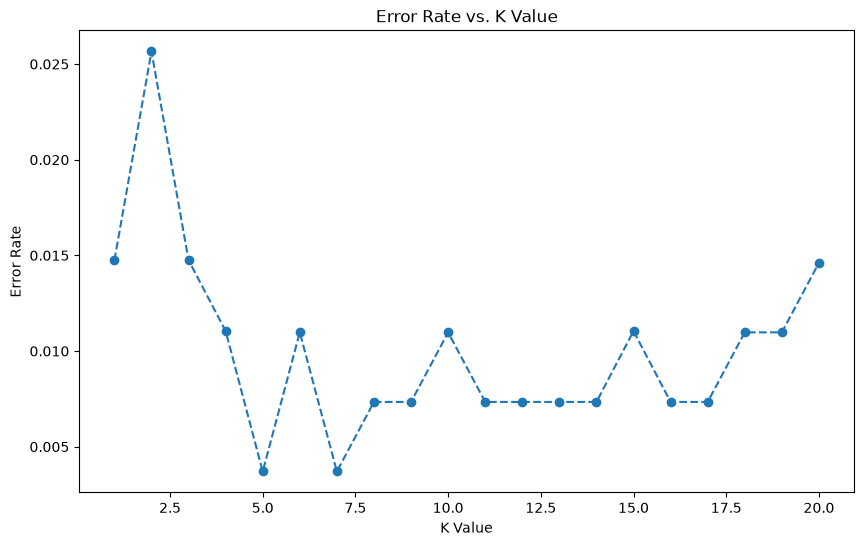

In [380]:

knn_pipeline = Pipeline(steps=[
    ('knn', KNeighborsClassifier())
])

grid_search = GridSearchCV(knn_pipeline, param_grid={'knn__n_neighbors': range(1, 21)}, cv=5, scoring='accuracy')

grid_search.fit(X_train, y_train.ravel())

error_rates = 1- grid_search.cv_results_['mean_test_score']

plt.figure(figsize=(10, 6))
plt.plot(range(1, 21), error_rates, marker='o', linestyle='--')
plt.title('Error Rate vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Error Rate')


#### 3.2 Importance of standardization and appropriate value of $K$ (5 points)

Explain why standardization is important for KNN and why a very small or very large value of $K$ may not perform well.

In [ ]:
Standardization is important for KNN because KNN classifies a point based on distances to its neighbors. If features are on very different scales, the distance calculation becomes dominated by the largest-scale features. For example, body mass and year are measured in different units and ranges, so a feature like body mass can overpower bill length or flipper length even when the latter is actually more informative.

Standardizing features (zero mean, unit variance) makes each feature contribute more fairly to the distance metric, so the model measures “true” neighborhood similarity rather than being biased by scale.

Why very small or very large K can perform poorly:
- Very small K (for example K=1):
    - The model is very sensitive to noise and outliers.
    - It can memorize training examples and overfit.
    - The decision boundary becomes irregular and unstable.
- Very large K:
    - The model averages over too many neighbors.
    - It smooths away local patterns and can underfit.
    - The decision boundary becomes too simple and may miss important class structure.
- Best K is usually a middle value that balances:
    - local structure detection
    - noise resistance
    - generalization to unseen data

In short: standardization ensures distance-based comparisons are fair, and choosing an appropriate K balances overfitting and underfitting.

#### 3.3. Evaluate the final KNN model (10 points)

After selecting $K$, evaluate the final model on the test data. Report:

- Test accuracy (1 point)
- Test error rate (1 point)
- Confusion matrix (1 point)
- Precision, recall, and F1-score for each species (3 points)
- A written interpretation of the results (4 points)

### 4. Streamlit application (50 points)

Create an interactive Streamlit application that allows a user to enter the characteristics of a new penguin and receive a predicted species.

The application must include:

- A title and short description of the project
- Input widgets for the predictor variables
- A button labeled **Predict Species**
- The predicted penguin species
- Predicted probabilities for the three classes
- The value of $K$ selected by cross-validation
- A brief explanation of the prediction

The dataset may be loaded directly from the public URL using:

```python
data_url = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/main/inst/extdata/penguins.csv"
)
df = pd.read_csv(data_url)
```

The app must be deployed publicly using [Streamlit Community Cloud](https://streamlit.io/cloud). Submit a public URL that opens without requiring the instructor to run the code locally.

####  Required submission files

Submit:

1. The Jupyter notebook used for the analysis
2. `app.py`, containing the Streamlit application
3. `requirements.txt`
4. A public GitHub repository link
5. A public Streamlit application link 
6. Any additional files required to run the application

Your GitHub repository should contain at least:

```text
penguin-classification/
├── app.py
├── requirements.txt
├── README.md
└── analysis.ipynb
```